*Author: Sherry. Part of the RSNA Knee Abnormality Detection team project.*

### Imports

In [24]:
try:
    from vllm import LLM, SamplingParams
except ImportError:
    !pip install -q vllm
    from vllm import LLM, SamplingParams

import os
import re
import cv2
import json
import glob
import math
import pydicom
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from vllm import LLM, SamplingParams
from joblib import Parallel, delayed
from sklearn.metrics import roc_auc_score

## EDA
### Looking at the Studies
An initial look at the studies tells us there are 12 binary labels alongside an identifier and the full text report:
- StudyInstanceUID - unique identifier for the study; matches the folder name under train_series/.
- Report - the free-text radiology report. May be in any of several languages, depending on the reporting institution.
- ACL - anterior cruciate ligament injury (0/1).
- MCL - medial collateral ligament injury (0/1).
- Medial Meniscus - medial meniscus tear (0/1).
- Lateral Meniscus - lateral meniscus tear (0/1).
- Medial OA - osteoarthritis of the medial tibiofemoral compartment (0/1).
- Lateral OA - osteoarthritis of the lateral tibiofemoral compartment (0/1).
- PF OA - patellofemoral osteoarthritis (0/1).
- Effusion - joint effusion / excess fluid (0/1).
- Synovitis - inflammation of the joint lining (0/1).
- Baker's - Baker's cyst (0/1).
- Contusion - bone contusion / bone bruise (0/1).
- Fracture - fracture (0/1).

The report is in more languages than english so we're going to want to translate all of them to a single language. To avoid the model noticing the translation difference as well as the language difference, maybe we'll apply the translation technique to all reports even the english ones? Consider the approaches. We can see we have 4407 studies and a total of 24371 data points (MRI acquisitions). Most of our study data is null, the relavent information is actually stored in the reports. Exactly 58 studies have relavent information and all 58 of them retain all the information. So we have 58 complete studies and 4349 null studies where data is in the report. Within the 58 complete studies there's a pretty large skew to mostly negatives for some datapoints like MCL which will likely bias the data. When we extract the information from the reports we'll have to look at that again and perhaps cut to make them more even or randomly select a certain amount.

In [25]:
# Setting up the base variables for later (base data url and label array)
BASE = '/kaggle/input/competitions/rsna-knee-abnormality-detection'
LABELS = ['ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']
TAGS = ['Rows', 'Columns', 'PixelSpacing', 'SliceThickness', 'SeriesDescription', 'Manufacturer']

train_info = pd.read_csv(f'{BASE}/train.csv')
train_info_series = pd.read_csv(f'{BASE}/train_series.csv')
sample_sub = pd.read_csv(f'{BASE}/sample_submission.csv')

# Want to view the general shape of our data
print("Shape train_info:", train_info.shape, "\nShape train_info Series:",train_info_series.shape, "\nShape Sample Submission:",sample_sub.shape)
train_info.head()

In [26]:
# Want to see how much of the data is actually useful to work on since most of it seems to be null and get a decent idea of the spread.
pos = (train_info[LABELS] == 1).sum()
neg = (train_info[LABELS] == 0).sum()
pos_rate = pos / (pos + neg)
order = pos_rate.sort_values(ascending=False).index
pos, neg, pos_rate = pos[order], neg[order], pos_rate[order]
summary = pd.DataFrame({'non_null': train_info[LABELS].notna().sum(), 'positives': pos, 'negatives': neg})
summary['pos_rate'] = pos_rate
summary['pct_labeled'] = summary['non_null'] / len(train_info) * 100
summary = summary.sort_values('positives', ascending=False)

print(f"Studies with at least one non-null label: "
      f"{train_info[LABELS].notna().any(axis=1).sum()}\n")
print(summary.round(4))

print("\nLabels-per-study distribution:")
print(train_info[LABELS].notna().sum(axis=1).value_counts().sort_index())

Studies with at least one non-null label: 58

                  non_null  positives  negatives  pos_rate  pct_labeled
Effusion                58         35         23    0.6034       1.3161
Synovitis               58         27         31    0.4655       1.3161
Medial Meniscus         58         26         32    0.4483       1.3161
ACL                     58         24         34    0.4138       1.3161
Lateral Meniscus        58         23         35    0.3966       1.3161
PF OA                   58         21         37    0.3621       1.3161
Contusion               58         19         39    0.3276       1.3161
Fracture                58         18         40    0.3103       1.3161
Medial OA               58         15         43    0.2586       1.3161
Baker's                 58         12         46    0.2069       1.3161
Lateral OA              58         11         47    0.1897       1.3161
MCL                     58          9         49    0.1552       1.3161

Labels-per-study 

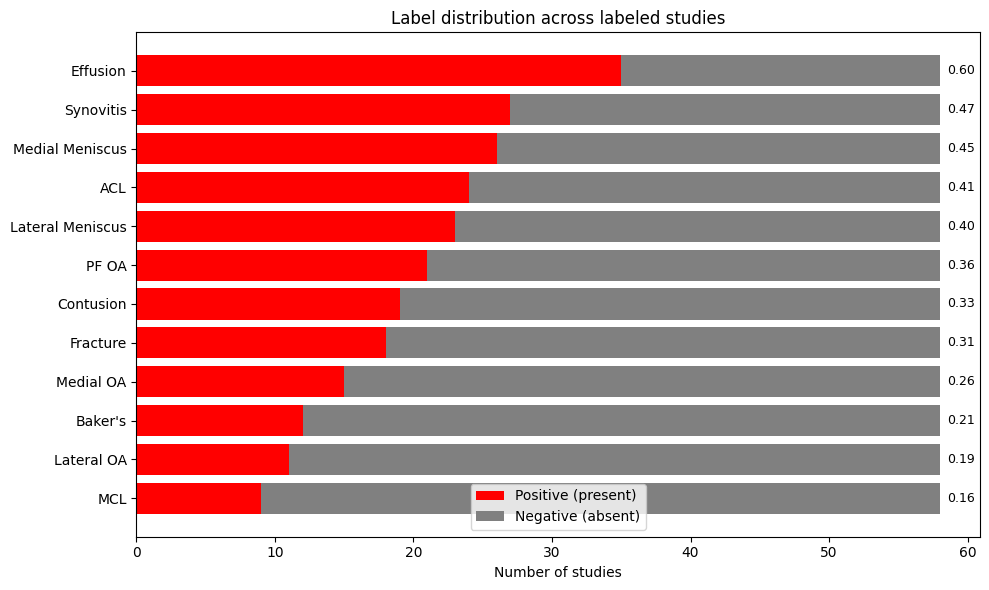

In [27]:
# Let's get some visuals in there to view the distribution as it exists of positive/negative non-nulls
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(order))

ax.barh(y, pos, color='red', label='Positive (present)')
ax.barh(y, neg, left=pos, color='grey', label='Negative (absent)')

ax.set_yticks(y)
ax.set_yticklabels(order)
ax.invert_yaxis()
ax.set_xlabel('Number of studies')
ax.set_title('Label distribution across labeled studies')
ax.legend(loc='lower center')

# Annotate positive rate at the end of each bar
for i, (p, n) in enumerate(zip(pos, neg)):
    ax.text(p + n + 0.5, i, f'{pos_rate.iloc[i]:.2f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

#### Looking at the Reports
Yeah going to need a language model to parse through all of that, maybe a basic RAG build as well to do it efficiently but two big things:
1. Multiple languages and no idea how much of which without manual or AI check
2. Multiple formats for how information including conclusions is shown so model will need a genuine understanding of the information
   - We probaly can't just do a basic scan through since there's nuance in the responses.

In [28]:
# Get a solid look at the report distributions
print("Rows:", len(train_info))
print("Nulls in Report:", train_info['Report'].isna().sum())
print("Empty strings:", (train_info['Report'].fillna('').str.strip() == '').sum())

# Character stats
train_info['report_len'] = train_info['Report'].fillna('').str.len()
print("\nCharacter length:")
print(train_info['report_len'].describe().round(1))

# Word count
train_info['report_words'] = train_info['Report'].fillna('').str.split().str.len()
print("\nWord count:")
print(train_info['report_words'].describe().round(1))

Rows: 4407
Nulls in Report: 0
Empty strings: 0

Character length:
count    4407.0
mean     1097.9
std       693.9
min        52.0
25%       587.5
50%       977.0
75%      1459.5
max      4743.0
Name: report_len, dtype: float64

Word count:
count    4407.0
mean      147.5
std        95.3
min         8.0
25%        74.5
50%       129.0
75%       202.0
max       690.0
Name: report_words, dtype: float64


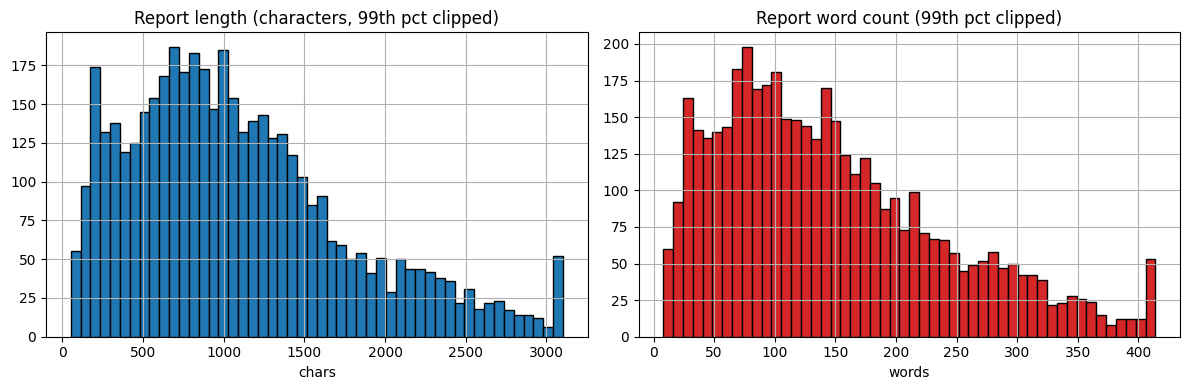

In [29]:
# Graph it cus why not
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_info['report_len'].clip(upper=train_info['report_len'].quantile(0.99)).hist(bins=50, ax=axes[0], edgecolor='black')
axes[0].set_title('Report length (characters, 99th pct clipped)')
axes[0].set_xlabel('chars')

train_info['report_words'].clip(upper=train_info['report_words'].quantile(0.99)).hist(bins=50, ax=axes[1], edgecolor='black', color='#d62728')
axes[1].set_title('Report word count (99th pct clipped)')
axes[1].set_xlabel('words')
plt.tight_layout()
plt.show()

In [30]:
# Actually look at some of the reports
sample = train_info.sample(n=5, random_state=42)

for i, row in sample.iterrows():
    print("=" * 100)
    print(f"StudyInstanceUID: {row['StudyInstanceUID']}")
    print("-" * 100)
    print(row['Report'])
    print()

### Looking at the Series
An initial look at the series data tells us there are 2 binary labels alongside a study identifier, a series identifier and an image:
- StudyInstanceUID - study this series belongs to.
- SeriesInstanceUID - unique identifier for the series; matches the folder name under train_series/<StudyInstanceUID>/.
- Fluid_Sensitive - 1 if the sequence emphasizes fluid signal (T2, PD, STIR, and similar), 0 otherwise.
- Fat_Suppression - 1 if the sequence applies fat suppression, 0 otherwise. Note that although Fluid_Sensitive and Fat_Suppression are often correlated, as observed in the training set, they are not necessarily equivalent for every case.
- Anatomical_Plane - imaging plane: Sagittal, Coronal, or Axial.

The (1,0) and (0,1) combinations don't seem to exist.

In [31]:
# Looking at an example series data point to get an understanding of it
study_id = train_info.iloc[0]['StudyInstanceUID']
series_dirs = glob.glob(f'{BASE}/train_series/{study_id}/*')
print(f"{len(series_dirs)} series for study {study_id}")
first_slice = sorted(glob.glob(f'{series_dirs[0]}/*.dcm'))[0]
ds = pydicom.dcmread(first_slice)
print("Modality: ", ds.Modality, "\nSeries Description: ", ds.SeriesDescription, "\nImage Shape: ", ds.pixel_array.shape)

5 series for study 1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260
Modality:  MR 
Series Description:  STIR CS_ AX 
Image Shape:  (560, 560)


In [32]:
labeled_studies = train_info.dropna(subset=LABELS)['StudyInstanceUID'].tolist()
print(f"{len(labeled_studies)} labeled studies")

candidates = train_info_series[train_info_series['StudyInstanceUID'].isin(labeled_studies) & (train_info_series['Anatomical_Plane'] == 'Sagittal') &(train_info_series['Fluid_Sensitive'] == 1)]
print(f"{len(candidates)} matching series\n")

# Peek at a few, with the study's labels so we know what to look for
for _, row in candidates.head(5).iterrows():
    labels = train_info.loc[train_info['StudyInstanceUID'] == row['StudyInstanceUID'], LABELS].iloc[0]
    positives = [l for l in LABELS if labels[l] == 1]
    print("Study ID", row['StudyInstanceUID'], "\nSeries ID", row['SeriesInstanceUID'], "\nPositives:", positives, "\n")

print("\ntrain_series columns:", list(train_info_series.columns))
print("\ntrain_series dtypes:\n", train_info_series.dtypes)
print("\nNull counts per column:\n", train_info_series.isna().sum())

58 labeled studies
64 matching series

Study ID 1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149 
Series ID 1.2.826.0.1.3680043.8.498.37372672584387115708078590109474719429 
Positives: ['PF OA', 'Effusion'] 

Study ID 1.2.826.0.1.3680043.8.498.10170898615867673028696505248839028269 
Series ID 1.2.826.0.1.3680043.8.498.55642842745139279565158267708282328638 
Positives: ['Lateral Meniscus', 'PF OA', 'Synovitis'] 

Study ID 1.2.826.0.1.3680043.8.498.10306159113324811538703788080836752052 
Series ID 1.2.826.0.1.3680043.8.498.10903465965639594231540335074980096554 
Positives: ['Medial Meniscus', 'Medial OA', 'PF OA', 'Synovitis'] 

Study ID 1.2.826.0.1.3680043.8.498.11287937729196958426538087439102017580 
Series ID 1.2.826.0.1.3680043.8.498.10819304863029245505396116222076917240 
Positives: ['Effusion'] 

Study ID 1.2.826.0.1.3680043.8.498.11287937729196958426538087439102017580 
Series ID 1.2.826.0.1.3680043.8.498.93698495301744954009961652118533312307 
Positives: ['Effusion

Anatomical_Plane
Sagittal    9864
Coronal     8609
Axial       5898
Name: count, dtype: int64

Fluid_Sensitive:
 Fluid_Sensitive
1    14010
0    10361
Name: count, dtype: int64

Fat_Suppression:
 Fat_Suppression
1    14010
0    10361
Name: count, dtype: int64

Plane × Fluid × Fat combo:
 Fat_Suppression                      0     1
Anatomical_Plane Fluid_Sensitive            
Axial            0                1179     0
                 1                   0  4719
Coronal          0                3985     0
                 1                   0  4624
Sagittal         0                5197     0
                 1                   0  4667


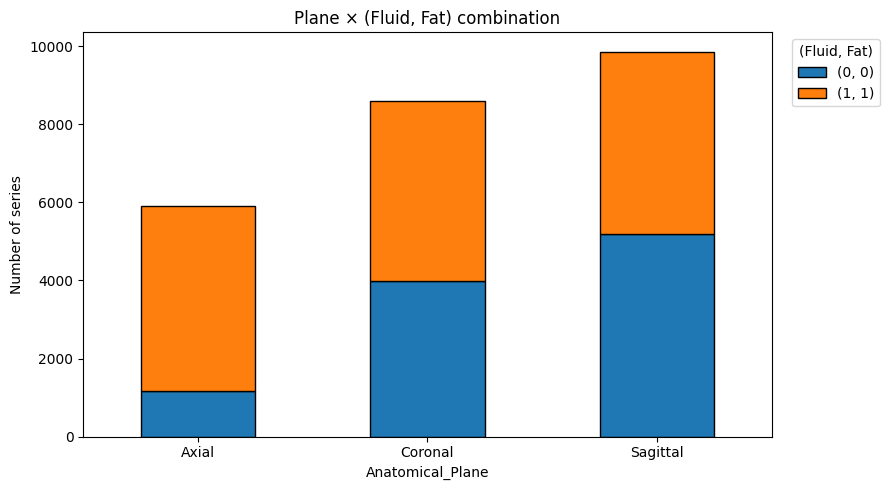

In [33]:
# Get a solid distribution so we know what the spread looks like
print(train_info_series['Anatomical_Plane'].value_counts(dropna=False))
print("\nFluid_Sensitive:\n", train_info_series['Fluid_Sensitive'].value_counts(dropna=False))
print("\nFat_Suppression:\n", train_info_series['Fat_Suppression'].value_counts(dropna=False))

combo = train_info_series.groupby(['Anatomical_Plane', 'Fluid_Sensitive', 'Fat_Suppression']).size().unstack(fill_value=0)
print("\nPlane × Fluid × Fat combo:\n", combo)

ct = pd.crosstab(train_info_series['Anatomical_Plane'],[train_info_series['Fluid_Sensitive'], train_info_series['Fat_Suppression']])
ct.plot(kind='bar', stacked=True, figsize=(9, 5), edgecolor='black')
plt.ylabel('Number of series')
plt.title('Plane × (Fluid, Fat) combination')
plt.xticks(rotation=0)
plt.legend(title='(Fluid, Fat)', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [34]:
# Load some of the actual series data
def load_series(study_uid, series_uid, max_slices=None):
    path = f'{BASE}/train_series/{study_uid}/{series_uid}'
    slices = [pydicom.dcmread(f) for f in glob.glob(f'{path}/*.dcm')]

    orient = np.array(slices[0].ImageOrientationPatient, float)
    normal = np.cross(orient[:3], orient[3:])
    slices.sort(key=lambda s: np.dot(normal, np.array(s.ImagePositionPatient, float)))

    if max_slices and len(slices) > max_slices:
        idx = np.linspace(0, len(slices) - 1, max_slices).astype(int)
        slices = [slices[i] for i in idx]
    return slices

# Show the images relavent to that series
def show_montage(slices, ncols=4, title=None):
    n = len(slices)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
    axes = np.array(axes).reshape(-1)

    for i, s in enumerate(slices):
        img = s.pixel_array.astype(float)
        lo, hi = np.percentile(img, [1, 99])
        img = np.clip((img - lo) / (hi - lo + 1e-8), 0, 1)
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(f"slice {i}", fontsize=8)
        axes[i].axis('off')

    for j in range(n, len(axes)):
        axes[j].axis('off')

    if title:
        fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.show()

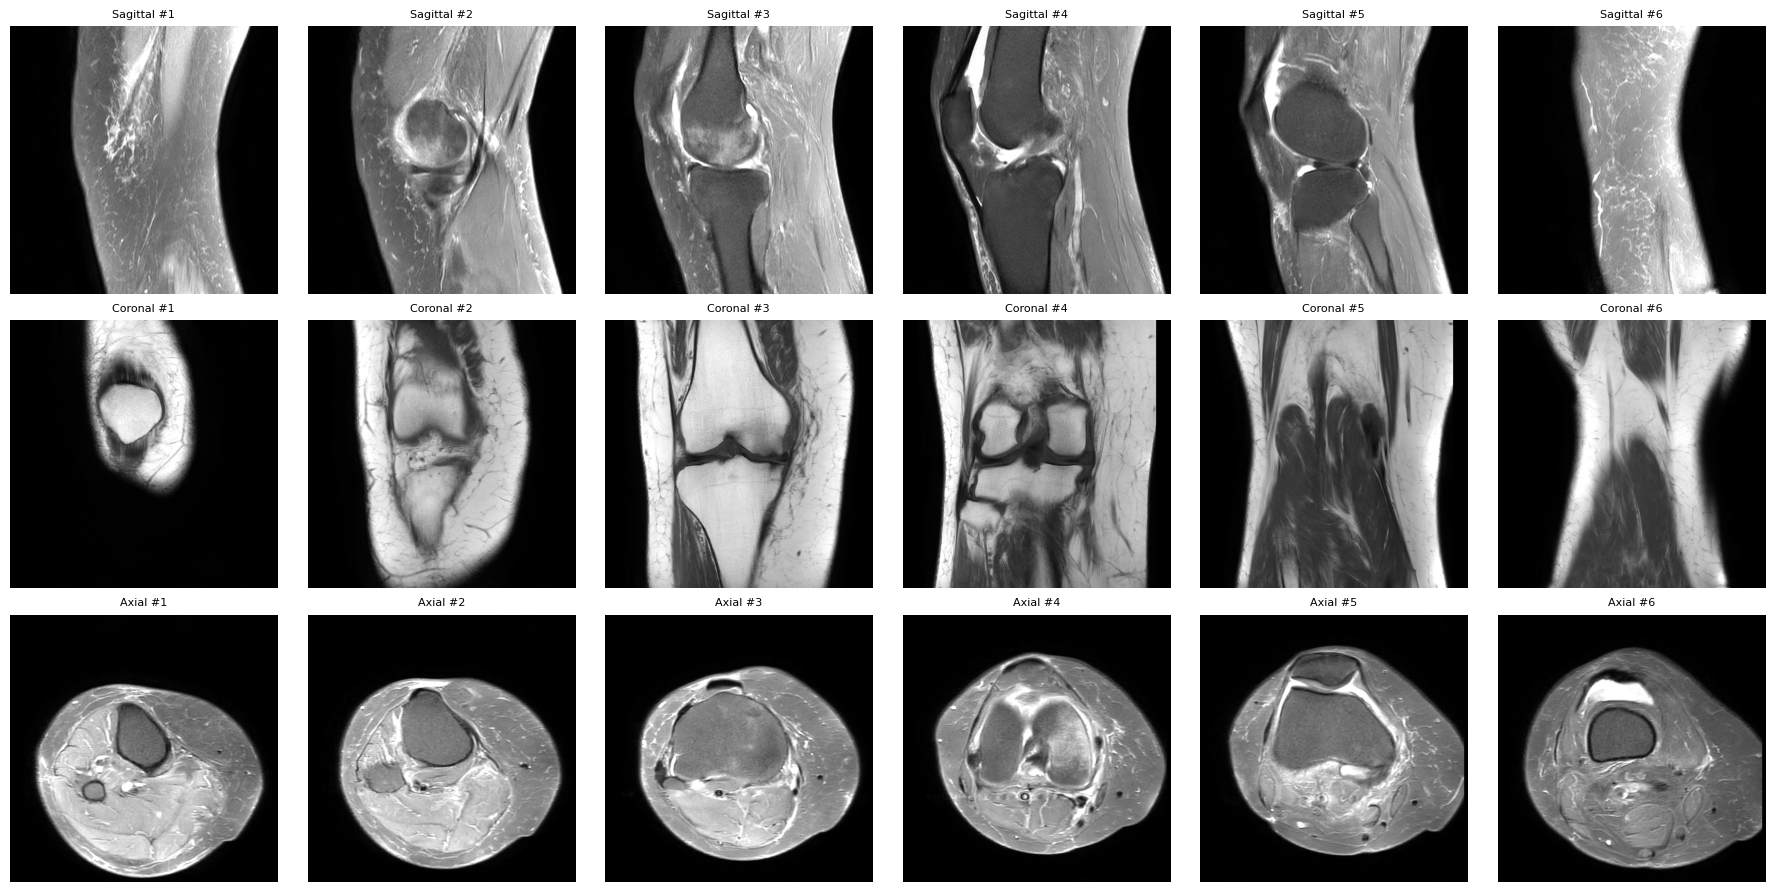

In [35]:
# Get a view of some of the actual images just for understanding honestly
study_uid = train_info_series['StudyInstanceUID'].iloc[0]
planes = ['Sagittal', 'Coronal', 'Axial']

fig, axes = plt.subplots(3, 6, figsize=(18, 9))
for r, plane in enumerate(planes):
    sub = train_info_series[(train_info_series['StudyInstanceUID'] == study_uid) & (train_info_series['Anatomical_Plane'] == plane)]
    s = load_series(sub.iloc[0]['StudyInstanceUID'], sub.iloc[0]['SeriesInstanceUID'], max_slices=6)
    for c in range(6):
        ax = axes[r, c]
        if c < len(s):
            img = s[c].pixel_array.astype(float)
            lo, hi = np.percentile(img, [1, 99])
            img = np.clip((img - lo) / (hi - lo + 1e-8), 0, 1)
            ax.imshow(img, cmap='gray')
        ax.set_title(f"{plane} #{c+1}", fontsize=8)
        ax.axis('off')

plt.tight_layout()
plt.show()

In [36]:
# Pull basic header info for every series
def series_info(study, series):
    path = f'{BASE}/train_series/{study}/{series}'
    files = sorted(f for f in os.listdir(path) if f.endswith('.dcm')) if os.path.isdir(path) else []
    if not files:
        return {'StudyInstanceUID': study, 'SeriesInstanceUID': series, 'n_slices': 0}
    h = pydicom.dcmread(f'{path}/{files[0]}', stop_before_pixels=True, specific_tags=TAGS)
    return {'StudyInstanceUID': study, 'SeriesInstanceUID': series,
            'n_slices': len(files),
            'rows': h.get('Rows'), 'cols': h.get('Columns'),
            'pixel_spacing': float(h.PixelSpacing[0]) if 'PixelSpacing' in h else None,
            'thickness': float(h.SliceThickness) if 'SliceThickness' in h else None,
            'description': h.get('SeriesDescription', ''),
            'manufacturer': h.get('Manufacturer', ''),
            'middle_file': f'{path}/{files[len(files) // 2]}'}

rows = Parallel(n_jobs=16, prefer='threads')(delayed(series_info)(st, se) for st, se in zip(train_info_series['StudyInstanceUID'], train_info_series['SeriesInstanceUID']))
series_meta = train_info_series.merge(pd.DataFrame(rows), on=['StudyInstanceUID', 'SeriesInstanceUID'])

# Does the CSV match the real data?
print("Series with no files:", (series_meta['n_slices'] == 0).sum())
print("Duplicate rows in train_series.csv:", train_info_series.duplicated().sum())
print("Series IDs used in more than one study:", (train_info_series.groupby('SeriesInstanceUID')['StudyInstanceUID'].nunique() > 1).sum())
print("Studies with no series:", (~train_info['StudyInstanceUID'].isin(train_info_series['StudyInstanceUID'])).sum())

# Duplicate slices inside a series: needs every header, so only check a sample
def n_unique_positions(study, series):
    path = f'{BASE}/train_series/{study}/{series}'
    pos = [pydicom.dcmread(f'{path}/{f}', stop_before_pixels=True, specific_tags=['ImagePositionPatient']).get('ImagePositionPatient') for f in os.listdir(path) if f.endswith('.dcm')]
    return len({tuple(p) for p in pos if p is not None})

sample = series_meta[series_meta['n_slices'] > 0].sample(300, random_state=42)
sample['n_unique_positions'] = Parallel(n_jobs=16, prefer='threads')(delayed(n_unique_positions)(st, se) for st, se in zip(sample['StudyInstanceUID'], sample['SeriesInstanceUID']))
dup_slices = sample[sample['n_unique_positions'] < sample['n_slices']]
print("\nSampled series with repeated slice positions:", len(dup_slices), "/ 300")
dup_slices[['StudyInstanceUID', 'SeriesInstanceUID', 'description', 'n_slices', 'n_unique_positions']].head()

Series with no files: 0
Duplicate rows in train_series.csv: 0
Series IDs used in more than one study: 0
Studies with no series: 0

Sampled series with repeated slice positions: 0 / 300


,StudyInstanceUID,SeriesInstanceUID,description,n_slices,n_unique_positions


manufacturer
Siemens Healthineers               5309
GE MEDICAL SYSTEMS                 4914
SIEMENS                            4460
Philips Medical Systems            3614
Philips                            3502
TOSHIBA                            1015
Philips Healthcare                  495
Siemens                             417
CANON_MEC                           328
GEHC                                187
FUJIFILM Healthcare Corporation      88
Hitachi Medical Corporation          42
Name: count, dtype: int64


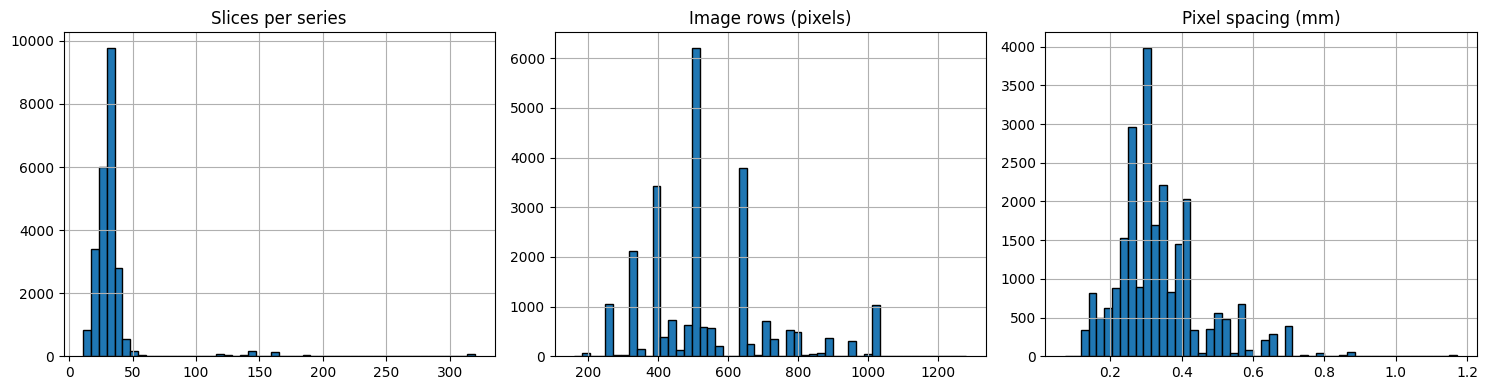

In [37]:
# Let's get a nice idea of the spread
print(series_meta['manufacturer'].value_counts())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
series_meta['n_slices'].hist(bins=50, ax=axes[0], edgecolor='black'); axes[0].set_title('Slices per series')
series_meta['rows'].hist(bins=50, ax=axes[1], edgecolor='black'); axes[1].set_title('Image rows (pixels)')
series_meta['pixel_spacing'].hist(bins=50, ax=axes[2], edgecolor='black'); axes[2].set_title('Pixel spacing (mm)')
plt.tight_layout()
plt.show()

### Processing Reports

In [38]:
llm = LLM(model='Qwen/Qwen2.5-7B-Instruct', tensor_parallel_size=2, dtype='half', max_model_len=4096)

(MainProcess pid=58) INFO 10-17 15:50:58 [api_utils.py:286] non-default args: {'dtype': 'half', 'max_model_len': 4096, 'tensor_parallel_size': 2, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-7B-Instruct'}


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

(MainProcess pid=58) INFO 10-17 15:51:21 [model.py:699] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=58) WARNING 10-17 15:51:21 [model.py:2442] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=58) INFO 10-17 15:51:21 [model.py:2109] Using max model len 4096
(MainProcess pid=58) INFO 10-17 15:51:21 [scheduler.py:308] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=58) INFO 10-17 15:51:21 [kernel.py:408] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])


tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (9 outputs left out)

Capturing CUDA graphs (FULL): 100%|██████████| 2/2 [00:00<00:00,  7.53it/s]


(Worker_TP0 pid=466) INFO 10-17 15:54:35 [model_runner.py:1087] Graph capturing finished in 14 secs, took 0.76 GiB
(Worker_TP1 pid=467) INFO 10-17 15:54:35 [model_runner.py:1087] Graph capturing finished in 14 secs, took 0.76 GiB
(Worker_TP0 pid=466) INFO 10-17 15:54:35 [gpu_worker.py:692] Available KV cache memory: 4.47 GiB
(Worker_TP0 pid=466) INFO 10-17 15:54:35 [gpu_worker.py:707] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.9200 is equivalent to --gpu-memory-utilization=0.8544 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.9856. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(Worker_TP1 pid=467) INFO 10-17 15:54:35 [gpu_worker.py:707] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.9200 is equivalent to --gpu-memory-utilization=0.8544 without CUDA graph memory profiling. To

Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:03<00:00, 10.06it/s]


(Worker_TP1 pid=467) INFO 10-17 15:55:15 [model_runner.py:1087] Graph capturing finished in 12 secs, took 0.42 GiB
(Worker_TP1 pid=467) INFO 10-17 15:55:15 [gpu_worker.py:892] CUDA graph pool memory: 0.42 GiB (actual), 0.96 GiB (estimated), difference: 0.54 GiB (127.4%).
(Worker_TP1 pid=467) INFO 10-17 15:55:15 [gpu_worker.py:955] Free memory on device (14.36/14.56 GiB) on startup. Desired GPU memory utilization is (0.92, 13.4 GiB). Actual usage is 7.4 GiB for consumed memory (weights + non-torch), 1.53 GiB for peak activation, and 0.42 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=4192991294` (3.91 GiB) to fit into requested memory, or `--kv-cache-memory=5231144448` (4.87 GiB) to fully utilize gpu memory. Current kv cache memory in use is 4.47 GiB.
(Worker_TP0 pid=466) INFO 10-17 15:55:15 [model_runner.py:1087] Graph capturing finished in 12 secs, took 0.42 GiB
(Worker_TP0 pid=466) INFO 10-17 15:55:15 [gpu_worker.py:892] CUDA graph pool memory

In [39]:
tok = llm.get_tokenizer()
ALL_LETTERS = ['A', 'B', 'C', 'D', 'E']
LETTER_ID = {l: tok.encode(l, add_special_tokens=False)[0] for l in ALL_LETTERS}

SYSTEM_PROMPT = "You read knee MRI radiology reports, which may be in any language. Answer with a single letter."

IDX_YES, IDX_NO, IDX_NOT_ADDRESSED, IDX_HEDGED = 0, 1, 2, 3
HEDGED_OPT = 'the report describes it as possible, suspected, equivocal, or cannot be excluded (hedged)'

# Order is fixed: A=present, B=absent, C=not addressed, D=hedged — for every finding.
YES_NO = ['yes', 'no, it is described as normal, intact or absent', 'the report does not address it', HEDGED_OPT]

EFFUSION_OPTS = ['effusion is present', 'no effusion (or only trace)', 'the report does not address it', HEDGED_OPT]

FINDINGS = {
    'ACL': {'question': 'Does the report say the anterior cruciate ligament (ACL) is torn?', 'options': YES_NO},
    'MCL': {'question': 'Does the report say the MEDIAL collateral ligament (MCL) is torn or injured (ignore the lateral collateral ligament)?', 'options': YES_NO},
    'Medial Meniscus': {'question': 'Does the report say the medial meniscus is torn?', 'options': YES_NO},
    'Lateral Meniscus': {'question': 'Does the report say the lateral meniscus is torn?', 'options': YES_NO},
    'Medial OA': {'question': 'Does the report say there is cartilage loss, chondral damage or osteoarthritis in the medial femorotibial compartment (medial femoral condyle or medial tibial plateau)?', 'options': YES_NO},
    'Lateral OA': {'question': 'Does the report say there is cartilage loss, chondral damage or osteoarthritis in the lateral femorotibial compartment (lateral femoral condyle or lateral tibial plateau)?', 'options': YES_NO},
    'PF OA': {'question': 'Does the report say there is cartilage loss, chondral damage or osteoarthritis of the patella or femoral trochlea?', 'options': YES_NO},
    'Effusion': {'question': 'Does the report say there is joint effusion (fluid in the knee joint)?', 'options': EFFUSION_OPTS},
    'Synovitis': {'question': 'Does the report say there is synovitis or synovial thickening?', 'options': YES_NO},
    "Baker's": {'question': "Does the report say there is a Baker's (popliteal) cyst?", 'options': YES_NO},
    'Contusion': {'question': 'Does the report say there is a bone contusion, bone bruise or bone marrow edema?', 'options': YES_NO},
    'Fracture': {'question': 'Does the report say there is a fracture?', 'options': YES_NO},
}

NEW_SUFFIXES = ('_not_addressed', '_hedged')

def prompt(report, finding):
    opts = '\n'.join(f'{ALL_LETTERS[i]}) {o}' for i, o in enumerate(finding['options']))
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": f"Report:\n{report}\n\nQuestion: {finding['question']}\n{opts}\nAnswer:"}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def label_reports(df, findings=FINDINGS):
    jobs = [(uid, rep, lab) for uid, rep in zip(df['StudyInstanceUID'], df['Report']) for lab in LABELS]
    prompts = [prompt(rep, findings[lab]) for _, rep, lab in jobs]
    params = [SamplingParams(max_tokens=1, temperature=0, logprobs=20, allowed_token_ids=[LETTER_ID[l] for l in ALL_LETTERS[:len(findings[lab]['options'])]]) for _, _, lab in jobs]
    outs = llm.generate(prompts, params)
    rows, missing = {}, 0
    for (uid, _, lab), out in zip(jobs, outs):
        options = findings[lab]['options']
        lp = out.outputs[0].logprobs[0]
        p = []
        for l in ALL_LETTERS[:len(options)]:
            t = LETTER_ID[l]
            p.append(math.exp(lp[t].logprob) if t in lp else 0.0)
            missing += t not in lp
        r = rows.setdefault(uid, {'StudyInstanceUID': uid})
        choice = int(np.argmax(p))
        r[lab] = int(choice == IDX_YES)
        r[f'{lab}_not_addressed'] = int(choice == IDX_NOT_ADDRESSED)
        r[f'{lab}_hedged'] = int(choice == IDX_HEDGED)
        r[f'{lab}_p_present'] = p[IDX_YES]
    if missing:
        print(f"warning: {missing} letter probabilities missing")
    return pd.DataFrame(rows.values())

def evaluate(probs):
    labeled = train_info[train_info['StudyInstanceUID'].isin(labeled_studies)]
    m = labeled[['StudyInstanceUID'] + LABELS].merge(probs, on='StudyInstanceUID', suffixes=('_label', '_pred'))
    return pd.Series({lab: roc_auc_score(m[f'{lab}_label'], m[f'{lab}_p_present']) for lab in LABELS})

In [40]:
labeled = train_info[train_info['StudyInstanceUID'].isin(labeled_studies)]

probs = label_reports(labeled)
auc = evaluate(probs)
print(auc.round(3), '\nmacro:', round(auc.mean(), 3))

m = labeled[['StudyInstanceUID'] + LABELS].merge(probs[['StudyInstanceUID'] + LABELS], on='StudyInstanceUID', suffixes=('_label', '_pred'))

summary = pd.DataFrame({
    lab: {
        'agree':     ((m[f'{lab}_pred'] > 0.5) == m[f'{lab}_label']).mean(),
        'false_pos': ((m[f'{lab}_pred'] > 0.5) & (m[f'{lab}_label'] == 0)).sum(),
        'false_neg': ((m[f'{lab}_pred'] <= 0.5) & (m[f'{lab}_label'] == 1)).sum(),
    } for lab in LABELS
}).T.round(3)
print(summary)

Rendering prompts:   0%|          | 0/696 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 696/696 [00:38<00:00, 18.04it/s, est. speed input: 9347.55 toks/s, output: 18.04 toks/s]

ACL                 0.912
MCL                 0.880
Medial Meniscus     0.923
Lateral Meniscus    0.886
Medial OA           0.896
Lateral OA          0.756
PF OA               0.834
Effusion            0.686
Synovitis           0.712
Baker's             0.877
Contusion           0.771
Fracture            0.878
dtype: float64 
macro: 0.834
                  agree  false_pos  false_neg
ACL               0.828        2.0        8.0
MCL               0.879        2.0        5.0
Medial Meniscus   0.845        3.0        6.0
Lateral Meniscus  0.862        1.0        7.0
Medial OA         0.828        7.0        3.0
Lateral OA        0.793        8.0        4.0
PF OA             0.793        4.0        8.0
Effusion          0.638       13.0        8.0
Synovitis         0.655        4.0       16.0
Baker's           0.862        7.0        1.0
Contusion         0.741        9.0        6.0
Fracture          0.776        5.0        8.0


In [41]:
# Minor cleanup, remove later
probs_all = label_reports(train_info)
probs_all.to_csv('/kaggle/working/report_labels.csv', index=False)

print(probs_all.shape)
print(probs_all[LABELS].describe().T[['mean', 'min', 'max']].round(3))

AUX = [f'{lab}{s}' for lab in LABELS for s in ('_not_addressed', '_hedged')]
out = probs_all[['StudyInstanceUID'] + LABELS + AUX].copy()

# Labeled studies get their real labels
out['is_labeled'] = out['StudyInstanceUID'].isin(labeled_studies)
true = train_info.set_index('StudyInstanceUID').loc[labeled_studies, LABELS]
out = out.set_index('StudyInstanceUID')
out.loc[labeled_studies, LABELS] = true
for lab in LABELS:
    out.loc[labeled_studies, f'{lab}_not_addressed'] = 0
    out.loc[labeled_studies, f'{lab}_hedged'] = 0
out = out.reset_index()

# Flag non-labeled studies whose report is identical to a labeled study's
labeled_reports = set(train_info.loc[train_info['StudyInstanceUID'].isin(labeled_studies), 'Report'].str.strip())
report_of = train_info.set_index('StudyInstanceUID')['Report'].str.strip()
out['duplicate_of_labeled'] = (~out['is_labeled']) & out['StudyInstanceUID'].map(report_of).isin(labeled_reports)

out.to_csv('/kaggle/working/training_labels.csv', index=False)
print(out.shape, '| labeled:', out['is_labeled'].sum(), '| duplicates of labeled:', out['duplicate_of_labeled'].sum())

Rendering prompts:   0%|          | 0/52884 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 52884/52884 [46:16<00:00, 19.04it/s, est. speed input: 8947.51 toks/s, output: 19.04 toks/s]     


(4407, 49)
                   mean  min  max
ACL               0.085  0.0  1.0
MCL               0.035  0.0  1.0
Medial Meniscus   0.291  0.0  1.0
Lateral Meniscus  0.122  0.0  1.0
Medial OA         0.264  0.0  1.0
Lateral OA        0.137  0.0  1.0
PF OA             0.273  0.0  1.0
Effusion          0.403  0.0  1.0
Synovitis         0.116  0.0  1.0
Baker's           0.273  0.0  1.0
Contusion         0.187  0.0  1.0
Fracture          0.057  0.0  1.0
(4407, 39) | labeled: 58 | duplicates of labeled: 1


### Processing Images
Let's get a quick processing version for others to work on but from going over this the processing is relatively simple. Duplicate removal, some level of grouping though depends on how the model is reading things.

In [42]:
# Settings + pick one series per study
IMG_SIZE = 224
N_SLICES = 24
RUN_ALL = True
# OUT_DIR = f'/kaggle/working/images_{PLANE.lower()}'
# os.makedirs(OUT_DIR, exist_ok=True)

# Fluid-sensitive series in this plane; if a study has more than one, keep the one with the most slices
# chosen = (series_meta[(series_meta['Anatomical_Plane'] == PLANE) & (series_meta['Fluid_Sensitive'] == 1)].sort_values('n_slices', ascending=False).drop_duplicates('StudyInstanceUID'))
# print(f"{len(chosen)} / {len(train_info)} studies have a {PLANE} fluid-sensitive series")

In [43]:
def process_series(study, series):
    try:
        vol = np.stack([cv2.resize(s.pixel_array.astype(np.float32), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA) for s in load_series(study, series)])
        vol = vol[np.linspace(0, len(vol) - 1, N_SLICES).round().astype(int)]
        lo, hi = np.percentile(vol, [1, 99])
        vol = np.clip((vol - lo) / (hi - lo + 1e-8), 0, 1)
        np.save(f'{OUT_DIR}/{study}.npy', (vol * 255).astype(np.uint8))
        return ''
    except Exception as e:
        return str(e)

for PLANE in ['Sagittal', 'Coronal', 'Axial']:
    OUT_DIR = f'/kaggle/working/images_{PLANE.lower()}'
    os.makedirs(OUT_DIR, exist_ok=True)

    # Fluid-sensitive series in this plane; if a study has more than one, keep the one with the most slices
    chosen = (series_meta[(series_meta['Anatomical_Plane'] == PLANE) & (series_meta['Fluid_Sensitive'] == 1)].sort_values('n_slices', ascending=False).drop_duplicates('StudyInstanceUID'))
    print(f"{len(chosen)} / {len(train_info)} studies have a {PLANE} fluid-sensitive series")

    todo = chosen if RUN_ALL else chosen.head(50)
    errors = Parallel(n_jobs=-1, verbose=5)(delayed(process_series)(st, se) for st, se in zip(todo['StudyInstanceUID'], todo['SeriesInstanceUID']))
    todo = todo.assign(error=errors)
    print("Failed:", (todo['error'] != '').sum())

    # Manifest: one row per study with its image file, labels and train/val split
    labels = pd.read_csv('/kaggle/working/training_labels.csv')
    done = todo.loc[todo['error'] == '', ['StudyInstanceUID', 'SeriesInstanceUID']]
    manifest = labels.merge(done, on='StudyInstanceUID')
    manifest['path'] = OUT_DIR + '/' + manifest['StudyInstanceUID'] + '.npy'
    manifest = manifest[~manifest['duplicate_of_labeled']]
    manifest['split'] = np.where(manifest['is_labeled'], 'val', 'train')
    manifest.to_csv(f'/kaggle/working/manifest_{PLANE.lower()}.csv', index=False)
    print(manifest['split'].value_counts())

4150 / 4407 studies have a Sagittal fluid-sensitive series


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:   17.2s
[Parallel(n_jobs=-1)]: Done  64 tasks      | elapsed:  1.4min
[Parallel(n_jobs=-1)]: Done 154 tasks      | elapsed:  2.1min
[Parallel(n_jobs=-1)]: Done 280 tasks      | elapsed:  2.4min
[Parallel(n_jobs=-1)]: Done 442 tasks      | elapsed:  2.6min
[Parallel(n_jobs=-1)]: Done 640 tasks      | elapsed:  3.0min
[Parallel(n_jobs=-1)]: Done 874 tasks      | elapsed:  3.4min
[Parallel(n_jobs=-1)]: Done 1144 tasks      | elapsed:  3.8min
[Parallel(n_jobs=-1)]: Done 1450 tasks      | elapsed:  4.3min
[Parallel(n_jobs=-1)]: Done 1792 tasks      | elapsed:  4.8min
[Parallel(n_jobs=-1)]: Done 2170 tasks      | elapsed

Failed: 0
split
train    4093
val        56
Name: count, dtype: int64
4248 / 4407 studies have a Coronal fluid-sensitive series


[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    1.6s
[Parallel(n_jobs=-1)]: Done  64 tasks      | elapsed:    7.5s
[Parallel(n_jobs=-1)]: Done 154 tasks      | elapsed:   17.7s
[Parallel(n_jobs=-1)]: Done 280 tasks      | elapsed:   30.1s
[Parallel(n_jobs=-1)]: Done 442 tasks      | elapsed:   46.4s
[Parallel(n_jobs=-1)]: Done 640 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 874 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done 1144 tasks      | elapsed:  2.0min
[Parallel(n_jobs=-1)]: Done 1450 tasks      | elapsed:  2.7min
[Parallel(n_jobs=-1)]: Done 1792 tasks      | elapsed:  3.4min
[Parallel(n_jobs=-1)]: Done 2170 tasks      | elapsed:  4.1min
[Parallel(n_jobs=-1)]: Done 2584 tasks      | elapsed:  4.8min
[Parallel(n_jobs=-1)]: Done 3034 tasks      | elapsed:  5.5min
[Parallel(n_jobs=-1)]: Done 3520 tasks      | elapsed:  6.1min
[Parallel(n_jobs=-1)]: Done 4042 tasks      | elapsed:  6.6min
[Parallel(n_jobs=-1)]: Done 4248 out of 4248 | elapsed:  6.8mi

Failed: 0
split
train    4191
val        56
Name: count, dtype: int64
4407 / 4407 studies have a Axial fluid-sensitive series


[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    8.2s
[Parallel(n_jobs=-1)]: Done  64 tasks      | elapsed:   52.2s
[Parallel(n_jobs=-1)]: Done 154 tasks      | elapsed:  2.6min
[Parallel(n_jobs=-1)]: Done 280 tasks      | elapsed:  4.4min
[Parallel(n_jobs=-1)]: Done 442 tasks      | elapsed:  5.1min
[Parallel(n_jobs=-1)]: Done 640 tasks      | elapsed:  5.5min
[Parallel(n_jobs=-1)]: Done 874 tasks      | elapsed:  6.0min
[Parallel(n_jobs=-1)]: Done 1144 tasks      | elapsed:  6.5min
[Parallel(n_jobs=-1)]: Done 1450 tasks      | elapsed:  7.1min
[Parallel(n_jobs=-1)]: Done 1792 tasks      | elapsed:  7.6min
[Parallel(n_jobs=-1)]: Done 2170 tasks      | elapsed:  8.3min
[Parallel(n_jobs=-1)]: Done 2584 tasks      | elapsed:  8.9min
[Parallel(n_jobs=-1)]: Done 3034 tasks      | elapsed:  9.6min
[Parallel(n_jobs=-1)]: Done 3520 tasks      | elapsed: 10.2min
[Parallel(n_jobs=-1)]: Done 4042 tasks      | elapsed: 10.9min


Failed: 0
split
train    4348
val        58
Name: count, dtype: int64


[Parallel(n_jobs=-1)]: Done 4407 out of 4407 | elapsed: 11.2min finished


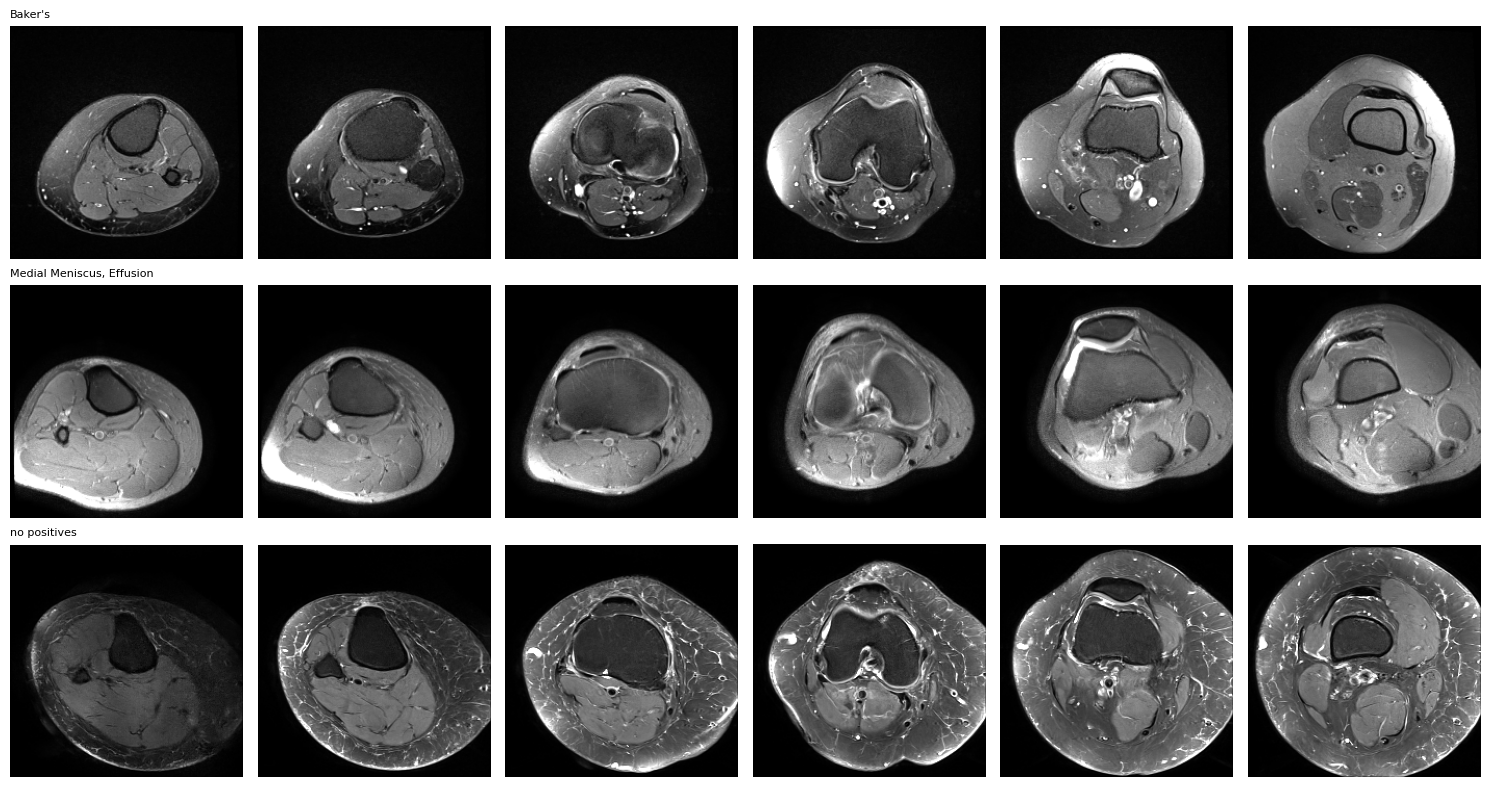

In [44]:
# Quick look at a few processed volumes with their labels
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for r, (_, row) in enumerate(manifest.sample(3, random_state=0).iterrows()):
    vol = np.load(row['path'])
    for c, i in enumerate(np.linspace(0, N_SLICES - 1, 6).astype(int)):
        axes[r, c].imshow(vol[i], cmap='gray')
        axes[r, c].axis('off')
    axes[r, 0].set_title(', '.join(l for l in LABELS if row[l] > 0.5) or 'no positives', fontsize=8, loc='left')
plt.tight_layout()
plt.show()

## Model Work